     annual_income  credit_score  employment_years  loan_approved
990          60446           592                 0              0
991          53707           515                28              0
992          61822           529                25              0
993          94393           683                24              1
994          55508           581                 3              0
995          56608           636                17              0
996          32328           612                18              0
997          75911           681                29              1
998          47768           590                 7              0
999         116439           683                29              1
       annual_income  credit_score  employment_years  loan_approved
count     1000.00000   1000.000000       1000.000000     1000.00000
mean     73556.29600    674.115000         15.058000        0.41600
std      26733.82271     99.980187          9.045134        0.49314
mi

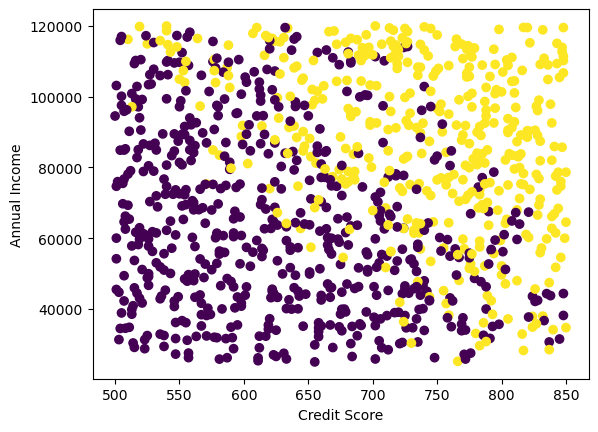

Accuracy : 0.82
Precision: 0.759493670886076
Recall   : 0.7792207792207793
F1 Score : 0.7692307692307693
Confusion Matrix:
 [[104  19]
 [ 17  60]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       123
           1       0.76      0.78      0.77        77

    accuracy                           0.82       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.82      0.82      0.82       200

Applicant 1: Rejected (P(approved) = 0.01)
Applicant 2: Approved (P(approved) = 0.58)
Applicant 3: Approved (P(approved) = 0.98)


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

data=pd.read_csv(r"C:\Users\Adithyan\Downloads\customer.csv")


print(data.tail(10))                      
print(data.describe())                    
print(data['loan_approved'].value_counts())  

# 3. Scatter plot
plt.scatter(data['credit_score'], data['annual_income'], c=data['loan_approved'])
plt.xlabel("Credit Score")
plt.ylabel("Annual Income")
plt.show()

# 5 & 6. Features and target
X = data[['annual_income', 'credit_score', 'employment_years']]
y = data['loan_approved']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 7. Evaluation
y_pred = model.predict(X_test)
y_train_pred=model.predict(X_train)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# 8. Predict for new applicants
new_applicants = pd.DataFrame({
    'annual_income':    [45000, 75000, 95000],
    'credit_score':     [680, 760, 810],
    'employment_years': [4, 8, 12]
})

pred = model.predict(new_applicants)
proba = model.predict_proba(new_applicants)

for i in range(len(new_applicants)):
    status = "Approved" if pred[i] == 1 else "Rejected"
    print(f"Applicant {i+1}: {status} (P(approved) = {proba[i][1]:.2f})")